# 🌦️ Madar — Day 2: Forecast baseline
**Goal:** prepare time-ordered data and compare a small LSTM with simple forecasts, on the same dates, horizon and metric.

Day 2 is about a **reliable foundation**, not the final model. The latest test period is **not used for tuning**.

## Evaluation setup (agreed Day 2)
- **Station:** KING KHALED INTL (Riyadh)
- **Target:** `air_temperature` (°C) | **Time step:** 1 hour | **Horizon:** next 24 hours
- **One value per hour:** readings at minute 0, repeated minute-0 readings averaged; no reading → NaN
- **Fake values (≥ 99)** → NaN; gaps are **not filled**
- **Train:** 2021-01-01 03:00 → 2023-12-31 23:00
- **Validation:** 2024-01-01 00:00 → 2024-11-28 23:00
- **Test:** 2025-01-01 03:00 → 2025-08-25 00:00 (untouched until final evaluation)
- The 794-hour gap (2024-11-29 → 2025-01-01) falls between validation and test
- **Known limit:** the test period has no September–December data
- **Input window:** 72 hours | **Seed:** 42
- **Metrics:** MAE (main) and RMSE, in °C
- **Evaluation:** repeated forecasts. Every hour with a complete 72 h input and a complete 24 h target (no NaN) is a forecast origin. **All models use the same origins.**
- Targets stay inside their split; inputs may use earlier data (already known at forecast time)
- **Scaler:** fit on training data only

## How this notebook follows the brief
- **Part 1** — Agree on the evaluation setup (sections 1.0–1.3)
- **Part 2 (morning)** — Parallel tracks: **A** simple forecasts, **B** first LSTM, **C** scaling, **D** improve window creation
- **Part 3 (afternoon)** — Bring the work together. ⚠️ The brief **reuses the letters**: afternoon **Track A** = complete sequence preparation, afternoon **Track B** = integrate forecast and evaluation. They are not the same as the morning A and B.

## Team rules for today
- One person integrates this notebook; others hand over tested cells or separate notebooks.
- Do not shuffle time order. Do not use random cross-validation.
- If training is slow or blocked: keep the baseline, write down the issue, ask the teaching team.

# Part 1 — Agree on the evaluation setup

## 1.0 Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

## 1.1 Build the hourly series
Same steps as notebook 01: one station, fake values → NaN, minute-0 readings, repeated readings averaged, full hourly calendar (missing hours stay NaN).

In [2]:
PATH = "../raw_data/saudi-hourly-weather-data.csv"
STATION = "KING KHALED INTL"
TZ = "Asia/Riyadh"

cols = ["station_name", "observation_date", "air_temperature"]
df = pd.read_csv(PATH, sep=";", usecols=cols)
df["observation_date"] = pd.to_datetime(df["observation_date"], utc=True).dt.tz_convert(TZ)
df["temp"] = df["air_temperature"].where(df["air_temperature"] < 99)   # fake codes -> NaN

s = df[df["station_name"] == STATION].sort_values("observation_date")
m0 = s[s["observation_date"].dt.minute == 0]
hourly = m0.groupby("observation_date")["temp"].mean()
hourly = hourly.reindex(pd.date_range(hourly.index.min(), hourly.index.max(), freq="h"))
hourly.name = "temp"

print("Hours:", len(hourly), "| NaN hours:", hourly.isna().sum())
print("Range:", hourly.index.min(), "→", hourly.index.max())
print("Sorted:", hourly.index.is_monotonic_increasing, "| Unique:", hourly.index.is_unique)
print("Min / max °C:", hourly.min(), "/", hourly.max())

Hours: 40726 | NaN hours: 2008
Range: 2021-01-01 03:00:00+03:00 → 2025-08-25 00:00:00+03:00
Sorted: True | Unique: True
Min / max °C: 1.95 / 48.0


## 1.2 Time split

In [3]:
WINDOW, HORIZON = 72, 24

SPLITS = {
    "train": ("2021-01-01 03:00", "2023-12-31 23:00"),
    "val":   ("2024-01-01 00:00", "2024-11-28 23:00"),
    "test":  ("2025-01-01 03:00", "2025-08-25 00:00"),
}

for name, (a, b) in SPLITS.items():
    part = hourly.loc[a:b]
    print(f"{name:5} | {part.index.min()} to {part.index.max()} | "
          f"{len(part):6} hours | NaN: {part.isna().sum()}")

train | 2021-01-01 03:00:00+03:00 to 2023-12-31 23:00:00+03:00 |  26277 hours | NaN: 644
val   | 2024-01-01 00:00:00+03:00 to 2024-11-28 23:00:00+03:00 |   7992 hours | NaN: 498
test  | 2025-01-01 03:00:00+03:00 to 2025-08-25 00:00:00+03:00 |   5662 hours | NaN: 72


## 1.3 Forecast origins (shared by all models)
An origin `t` is valid when the 72 inputs (`t-71 … t`) and the 24 targets (`t+1 … t+24`) have no NaN, and all targets are inside the split.

In [4]:
y, idx = hourly.to_numpy(), hourly.index

def origins(split):
    a, b = (pd.Timestamp(x, tz=TZ) for x in SPLITS[split])
    out = []
    for i in range(WINDOW - 1, len(y) - HORIZON):
        if not (a <= idx[i + 1] and idx[i + HORIZON] <= b):      # targets inside the split
            continue
        if np.isnan(y[i - WINDOW + 1 : i + HORIZON + 1]).any():  # no gap in input or target
            continue
        out.append(idx[i])
    return pd.DatetimeIndex(out)

ORIGINS = {name: origins(name) for name in SPLITS}
for name, o in ORIGINS.items():
    print(f"{name:5} | origins: {len(o):6} | first: {o[0]} | last: {o[-1]}")

train | origins:  18246 | first: 2021-01-04 02:00:00+03:00 | last: 2023-12-28 00:00:00+03:00
val   | origins:   4321 | first: 2024-01-04 02:00:00+03:00 | last: 2024-11-25 23:00:00+03:00
test  | origins:   2992 | first: 2025-01-04 02:00:00+03:00 | last: 2025-08-23 04:00:00+03:00


### Check a window by hand

In [5]:
def describe_origin(t):
    t = pd.Timestamp(t, tz=TZ)
    i = idx.get_loc(t)
    window = hourly.iloc[i - WINDOW + 1 : i + HORIZON + 1]
    nan_hours = window[window.isna()].index
    print("origin :", t)
    print("inputs :", idx[i - WINDOW + 1], "to", idx[i])
    print("targets:", idx[i + 1], "to", idx[i + HORIZON])
    if len(nan_hours):
        print(f"NaN    : {len(nan_hours)} hours, {nan_hours[0]} to {nan_hours[-1]}")
    else:
        print("NaN    : none")
    print("valid  :", any(t in o for o in ORIGINS.values()))
    print()

describe_origin("2024-03-05 12:00")   # invalid: gap on 2024-03-02 inside the inputs
describe_origin("2024-03-05 23:00")   # nearest valid origin after the gap

origin : 2024-03-05 12:00:00+03:00
inputs : 2024-03-02 13:00:00+03:00 to 2024-03-05 12:00:00+03:00
targets: 2024-03-05 13:00:00+03:00 to 2024-03-06 12:00:00+03:00
NaN    : 11 hours, 2024-03-02 13:00:00+03:00 to 2024-03-02 23:00:00+03:00
valid  : False

origin : 2024-03-05 23:00:00+03:00
inputs : 2024-03-03 00:00:00+03:00 to 2024-03-05 23:00:00+03:00
targets: 2024-03-06 00:00:00+03:00 to 2024-03-06 23:00:00+03:00
NaN    : none
valid  : True



# Part 2 — Parallel tracks (morning)
Each track works in its own notebook or cells and hands over **tested** cells to the integrator.
By late morning: a **minimal working window builder** and a **training-only scaler** are handed off (they become Part 3, afternoon Track A).

## Track A — Simple forecasts
Is the LSTM better than a simple forecast? Same forecast dates (`ORIGINS["val"]`) and metric for every approach.
- [ ] **Last-value:** repeat the last observed value (at `t`) across the 24-hour horizon
- [ ] **Seasonal naive:** same hour yesterday (repeat the last 24 hours) — a clear daily season exists (notebook 01, Task B)
- [ ] MAE and RMSE in °C
- [ ] **Save the predictions** with their dates, not only the score
- [ ] Plot: where the simple forecast does well and where it fails

Needs only Part 1 (no scaling, no windows).

# A1:Baseline Predictions

In [6]:
# A1. Actual values and baseline predictions for one split
#   row = one forecast origin t, column = horizon h = 1 … 24 (target time t + h)
STEPS = np.arange(1, HORIZON + 1)

def baseline_forecasts(split):
    o = ORIGINS[split]
    pos = idx.get_indexer(o)                              # position of t in the series
    actual = y[pos[:, None] + STEPS]                      # y[t+1 … t+24]
    preds = {
        "last_value": np.repeat(y[pos][:, None], HORIZON, axis=1),   # y[t] for every hour
        "seasonal_naive": y[pos[:, None] + STEPS - 24],              # y[t+h-24] = same hour yesterday
    }
    return o, actual, preds

val_origins, val_actual, val_preds = baseline_forecasts("val")

# Leakage check: every value used by a baseline is at or before t
assert (STEPS - 24 <= 0).all()
print("origins:", len(val_origins), "| actual shape:", val_actual.shape)
print("NaN in actual:", np.isnan(val_actual).sum(),
      "| NaN in preds:", {k: int(np.isnan(v).sum()) for k, v in val_preds.items()})

origins: 4321 | actual shape: (4321, 24)
NaN in actual: 0 | NaN in preds: {'last_value': 0, 'seasonal_naive': 0}


# A2: MAE and RMSE

In [7]:
# A2. MAE and RMSE in °C (validation, same origins for every approach)
def mae(a, p):  return float(np.mean(np.abs(a - p)))
def rmse(a, p): return float(np.sqrt(np.mean((a - p) ** 2)))

results = pd.DataFrame([
    {"approach": name, "split": "val", "origins": len(val_origins),
     "MAE": mae(val_actual, p), "RMSE": rmse(val_actual, p)}
    for name, p in val_preds.items()
]).round(3)
results

,approach,split,origins,MAE,RMSE
0,last_value,val,4321,5.078,6.332
1,seasonal_naive,val,4321,1.701,2.418


# A3: Save the predictions with their dates

In [8]:
# A3. Save the predictions with their dates (long format: one row per origin and horizon)
pred_df = pd.DataFrame({
    "origin": np.repeat(val_origins, HORIZON),
    "horizon": np.tile(STEPS, len(val_origins)),
    "actual": val_actual.ravel(),
    **{name: p.ravel() for name, p in val_preds.items()},
})
pred_df["target_time"] = pred_df["origin"] + pd.to_timedelta(pred_df["horizon"], unit="h")
pred_df = pred_df[["origin", "target_time", "horizon", "actual", *val_preds]]

os.makedirs("../reports/predictions", exist_ok=True)
pred_df.to_csv("../reports/predictions/baselines_val.csv", index=False)
results.to_csv("../reports/predictions/baselines_val_scores.csv", index=False)
print(pred_df.shape)
pred_df.head()

(103704, 6)


,origin,target_time,horizon,actual,last_value,seasonal_naive
0,2024-01-04 02:00:00+03:00,2024-01-04 03:00:00+03:00,1,13.85,14.0,17.05
1,2024-01-04 02:00:00+03:00,2024-01-04 04:00:00+03:00,2,13.00,14.0,17.00
2,2024-01-04 02:00:00+03:00,2024-01-04 05:00:00+03:00,3,13.00,14.0,16.00
3,2024-01-04 02:00:00+03:00,2024-01-04 06:00:00+03:00,4,12.05,14.0,15.90
4,2024-01-04 02:00:00+03:00,2024-01-04 07:00:00+03:00,5,12.00,14.0,15.00


# A4: Where the simple forecasts do well and where they fail

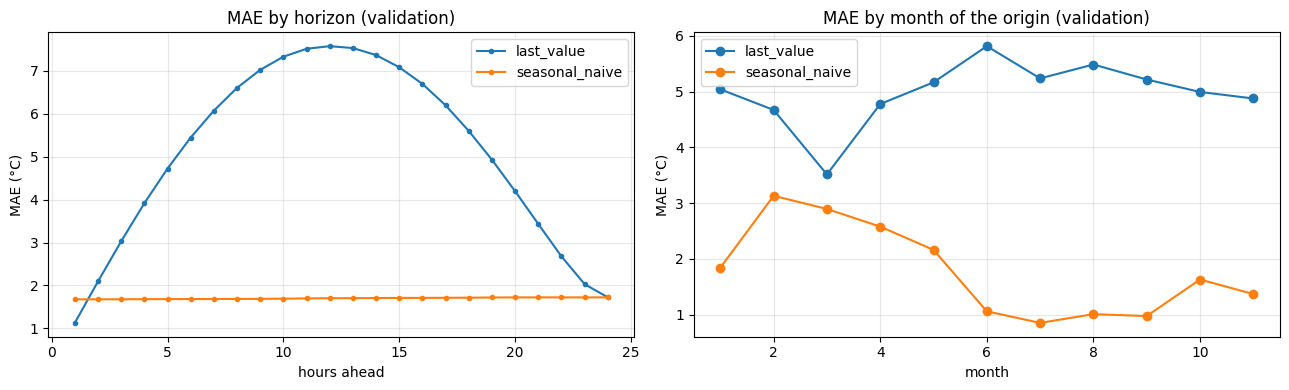

In [9]:
# A4. Where the simple forecasts do well and where they fail
err = {name: np.abs(val_actual - p) for name, p in val_preds.items()}
month = val_origins.month

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, e in err.items():
    ax[0].plot(STEPS, e.mean(axis=0), marker="o", ms=3, label=name)
    pd.Series(e.mean(axis=1)).groupby(month).mean().plot(ax=ax[1], marker="o", label=name)
ax[0].set(title="MAE by horizon (validation)", xlabel="hours ahead", ylabel="MAE (°C)")
ax[1].set(title="MAE by month of the origin (validation)", xlabel="month", ylabel="MAE (°C)")
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
fig.savefig("../reports/figures/04_baselines_error.png", dpi=150, bbox_inches="tight")

# A5: Example forecasts: best, typical and worst day for seasonal naive

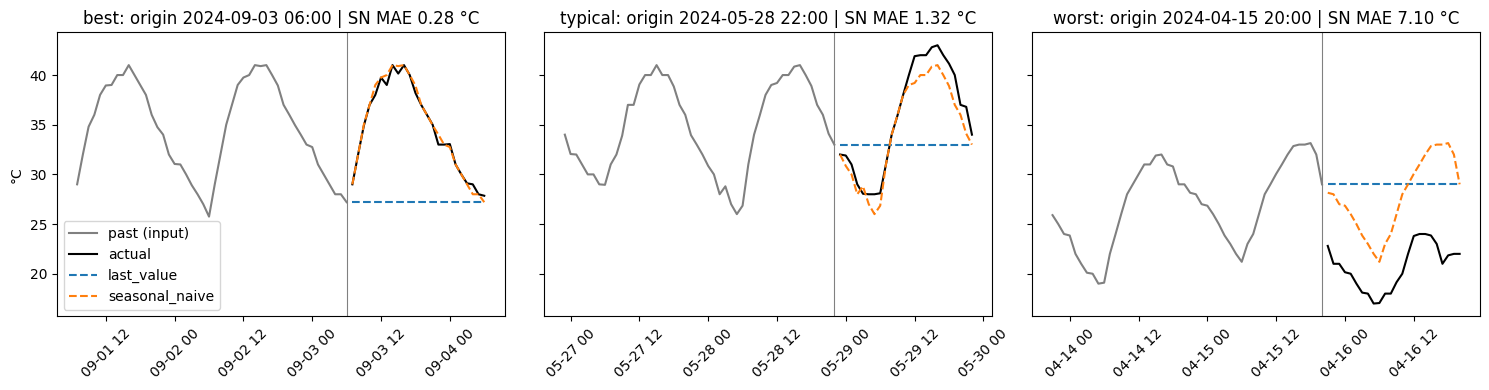

In [10]:
# A5. Example forecasts: best, typical and worst day for seasonal naive
day_err = err["seasonal_naive"].mean(axis=1)
picks = {"best": day_err.argmin(),
         "typical": np.abs(day_err - np.median(day_err)).argmin(),
         "worst": day_err.argmax()}

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (label, k) in zip(ax, picks.items()):
    t = val_origins[k]
    past = hourly.loc[t - pd.Timedelta(hours=47): t]
    a.plot(past.index, past.values, color="grey", label="past (input)")
    tt = t + pd.to_timedelta(STEPS, unit="h")
    a.plot(tt, val_actual[k], color="black", label="actual")
    for name, p in val_preds.items():
        a.plot(tt, p[k], "--", label=name)
    a.axvline(t, color="grey", lw=0.8)
    a.set_title(f"{label}: origin {t:%Y-%m-%d %H:%M} | SN MAE {day_err[k]:.2f} °C")
    a.tick_params(axis="x", rotation=45)
ax[0].set_ylabel("°C"); ax[0].legend()
plt.tight_layout()
fig.savefig("../reports/figures/05_baselines_examples.png", dpi=150, bbox_inches="tight")

## Track B — Build the first LSTM
- [ ] Create input sequences (72 past hours) and targets (next 24 hours) from `ORIGINS` — **raw rows are already split by date in Part 1**
- [ ] Keep it simple: windows for **train** and **validation** only
- [ ] Check a few windows by hand: inputs come before targets (`describe_origin`)
- [ ] Use only information available at forecast time (past temperature only)
- [ ] Fit scalers on **training data only** (same rule as Track C; Part 3 keeps one shared scaler)
- [ ] One small LSTM, one short training run; do not shuffle the time split
- [ ] Use validation to choose settings; report error in °C
- [ ] Keep window, horizon and features fixed; no extra input columns, no several LSTM designs today

# B1:Sequences for train and validation (raw °C)

In [11]:
OFFS_X = np.arange(-WINDOW + 1, 1)          # t-71 … t   (72 past hours)
OFFS_Y = np.arange(1, HORIZON + 1)          # t+1 … t+24 (next 24 hours)

def make_xy(split):
    pos = idx.get_indexer(ORIGINS[split])
    X = y[pos[:, None] + OFFS_X][..., None]   # (n, 72, 1)
    Y = y[pos[:, None] + OFFS_Y]              # (n, 24)
    return X, Y

X_train_raw, y_train_raw = make_xy("train")
X_val_raw,   y_val_raw   = make_xy("val")

print("X_train:", X_train_raw.shape, "| y_train:", y_train_raw.shape)
print("X_val  :", X_val_raw.shape,   "| y_val  :", y_val_raw.shape)
print("NaN:", np.isnan(X_train_raw).sum() + np.isnan(y_train_raw).sum()
              + np.isnan(X_val_raw).sum() + np.isnan(y_val_raw).sum())
print("Same targets as Track A:", np.allclose(y_val_raw, val_actual))

# Check one window by hand: last input = value at t, first target = value at t+1
k = 0
t = ORIGINS["val"][k]
print("\norigin", t)
print("last input  =", X_val_raw[k, -1, 0], "| hourly[t]   =", hourly[t])
print("first target=", y_val_raw[k, 0],     "| hourly[t+1] =", hourly[t + pd.Timedelta(hours=1)])

X_train: (18246, 72, 1) | y_train: (18246, 24)
X_val  : (4321, 72, 1) | y_val  : (4321, 24)
NaN: 0
Same targets as Track A: True

origin 2024-01-04 02:00:00+03:00
last input  = 14.0 | hourly[t]   = 14.0
first target= 13.85 | hourly[t+1] = 13.85


# B2: Scaling(Train only )

In [12]:
train_vals = hourly.loc[SPLITS["train"][0]:SPLITS["train"][1]].dropna()
MU, SIGMA = float(train_vals.mean()), float(train_vals.std())
def to_scaled(x):  return (x - MU) / SIGMA
def to_celsius(z): return z * SIGMA + MU
print(f"scaler from train only: mean = {MU:.3f} °C | std = {SIGMA:.3f} °C")

X_train, y_train = to_scaled(X_train_raw), to_scaled(y_train_raw)
X_val,   y_val   = to_scaled(X_val_raw),   to_scaled(y_val_raw)
print("train targets scaled: mean", round(float(y_train.mean()), 3), "| std", round(float(y_train.std()), 3))
print("val   targets scaled: mean", round(float(y_val.mean()), 3),   "| std", round(float(y_val.std()), 3))
assert np.allclose(to_celsius(y_val), y_val_raw)   # scaling can be reversed exactly

scaler from train only: mean = 27.678 °C | std = 9.420 °C
train targets scaled: mean -0.036 | std 1.01
val   targets scaled: mean 0.201 | std 0.935


# B3: One small LSTM, one short training run

In [13]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)

LSTM_CONFIG = {"units": 32, "max_epochs": 20, "batch_size": 64, "lr": 1e-3, "patience": 3,
               "window": WINDOW, "horizon": HORIZON, "features": ["temp"]}

model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(LSTM_CONFIG["units"]),
    layers.Dense(HORIZON),                      # 24 outputs: t+1 … t+24
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=LSTM_CONFIG["lr"]), loss="mse")
model.summary()

es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=LSTM_CONFIG["patience"],
                                   restore_best_weights=True)

# shuffle=True only mixes training windows; validation stays the later period
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=LSTM_CONFIG["max_epochs"], batch_size=LSTM_CONFIG["batch_size"],
                    shuffle=True, callbacks=[es], verbose=1)

2026-10-12 16:48:22.685525: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-12 16:48:22.717753: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-12 16:48:22.766267: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-12 16:48:22.817870: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-12 16:48:22.817988: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-12 16:48:22.895751: I tensorflow/core/platform/cpu_feature_guard.cc:

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,144 (20.09 KB)

 Trainable params: 5,144 (20.09 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - loss: 0.2837 - val_loss: 0.0678
Epoch 2/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - loss: 0.0688 - val_loss: 0.0593
Epoch 3/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - loss: 0.0622 - val_loss: 0.0548
Epoch 4/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - loss: 0.0581 - val_loss: 0.0520
Epoch 5/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - loss: 0.0555 - val_loss: 0.0504
Epoch 6/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - loss: 0.0539 - val_loss: 0.0495
Epoch 7/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/step - loss: 0.0529 - val_loss: 0.0489
Epoch 8/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - loss: 0.0521 - val_loss: 0.0483
Epoch 9/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - loss: 0.0512 - val_loss: 0.0478
Epoch 10/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - loss: 0.0503 - val_loss: 0.0476
Epoch 11/20
286/286 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - loss: 0.0495 - val_loss: 0.0474
Epoch 12/20
286/286 ━━━━━━━━━━━

# B4 : LSTM error in °C vs baselines

{'units': 32, 'max_epochs': 20, 'batch_size': 64, 'lr': 0.001, 'patience': 3, 'window': 72, 'horizon': 24, 'features': ['temp'], 'epochs_run': 20, 'best_epoch': 18}


,approach,split,origins,MAE,RMSE
0,last_value,val,4321,5.078,6.332
1,seasonal_naive,val,4321,1.701,2.418
2,lstm,val,4321,1.456,2.019


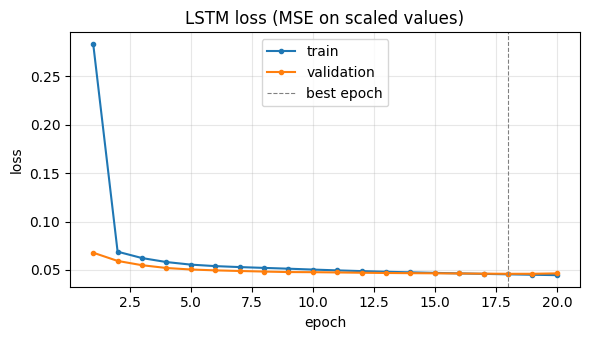

In [14]:
val_pred_lstm = to_celsius(model.predict(X_val, verbose=0))
assert val_pred_lstm.shape == val_actual.shape
val_preds["lstm"] = val_pred_lstm

LSTM_CONFIG["epochs_run"] = len(history.history["loss"])
LSTM_CONFIG["best_epoch"] = int(np.argmin(history.history["val_loss"])) + 1

lstm_row = {"approach": "lstm", "split": "val", "origins": len(val_origins),
            "MAE": mae(val_actual, val_pred_lstm), "RMSE": rmse(val_actual, val_pred_lstm)}
results = pd.concat([results[results["approach"] != "lstm"], pd.DataFrame([lstm_row])],
                    ignore_index=True).round(3)
print(LSTM_CONFIG)
display(results)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, LSTM_CONFIG["epochs_run"] + 1), history.history["loss"], marker="o", ms=3, label="train")
ax.plot(range(1, LSTM_CONFIG["epochs_run"] + 1), history.history["val_loss"], marker="o", ms=3, label="validation")
ax.axvline(LSTM_CONFIG["best_epoch"], color="grey", ls="--", lw=0.8, label="best epoch")
ax.set(title="LSTM loss (MSE on scaled values)", xlabel="epoch", ylabel="loss")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
fig.savefig("../reports/figures/06_lstm_loss.png", dpi=150, bbox_inches="tight")

## Track C — Prepare scaling
- [ ] Create a small example window by hand and confirm its input dates come before its target dates
- [ ] Fit the scaler on **training values only**
- [ ] Use that fitted scaler for validation (and later test) values
- [ ] Keep a way to reverse the scaling (errors in °C)

# C1: Small example window by hand (inputs before targets)

In [15]:
# C1. Small example window by hand: inputs must come BEFORE targets
t = ORIGINS["val"][0]                      # a valid forecast origin
i = idx.get_loc(t)

small_in  = hourly.iloc[i - 4 : i + 1]     # 5 past hours  (t-4 … t)
small_tgt = hourly.iloc[i + 1 : i + 4]     # 3 next hours  (t+1 … t+3)

print("origin        :", t)
print("input  dates  :", small_in.index[0], "→", small_in.index[-1])
print("target dates  :", small_tgt.index[0], "→", small_tgt.index[-1])
print("input values  :", small_in.round(1).tolist())
print("target values :", small_tgt.round(1).tolist())

assert small_in.index.max() < small_tgt.index.min()                           # inputs before targets
assert small_tgt.index.min() - small_in.index.max() == pd.Timedelta(hours=1)  # no gap between them
print("✔ small window: inputs come before targets\n")

# Same check on ALL real windows (72 inputs, 24 targets) for every split
OFFS_X = np.arange(-WINDOW + 1, 1)
OFFS_Y = np.arange(1, HORIZON + 1)
t_ns = idx.asi8                                # timestamps as integers (ns)
HOUR = pd.Timedelta(hours=1).value

for name in SPLITS:
    pos = idx.get_indexer(ORIGINS[name])
    in_t  = t_ns[pos[:, None] + OFFS_X]
    tgt_t = t_ns[pos[:, None] + OFFS_Y]
    assert (in_t[:, -1] < tgt_t[:, 0]).all()               # last input < first target
    assert (np.diff(in_t, axis=1) == HOUR).all()           # inputs are consecutive hours
    assert (np.diff(tgt_t, axis=1) == HOUR).all()          # targets are consecutive hours
    print(f"✔ {name:5}: {len(pos)} windows, inputs always before targets")

origin        : 2024-01-04 02:00:00+03:00
input  dates  : 2024-01-03 22:00:00+03:00 → 2024-01-04 02:00:00+03:00
target dates  : 2024-01-04 03:00:00+03:00 → 2024-01-04 05:00:00+03:00
input values  : [15.0, 15.0, 14.9, 15.0, 14.0]
target values : [13.8, 13.0, 13.0]
✔ small window: inputs come before targets

✔ train: 18246 windows, inputs always before targets
✔ val  : 4321 windows, inputs always before targets
✔ test : 2992 windows, inputs always before targets


# C2: Fit the scaler on training values only

In [16]:
# C2. Fit the scaler on TRAINING values only
train_vals = hourly.loc[SPLITS["train"][0]:SPLITS["train"][1]].dropna()

MU, SIGMA = float(train_vals.mean()), float(train_vals.std())

def to_scaled(x):  return (x - MU) / SIGMA       # °C -> scaled
def to_celsius(z): return z * SIGMA + MU         # scaled -> °C (reverse)

print(f"scaler (train only): mean = {MU:.3f} °C | std = {SIGMA:.3f} °C | n = {len(train_vals)}")

# Sanity check: train values become mean ≈ 0 and std ≈ 1
z_train = to_scaled(train_vals.to_numpy())
print("train scaled: mean =", round(float(z_train.mean()), 4), "| std =", round(float(z_train.std(ddof=1)), 4))

scaler (train only): mean = 27.678 °C | std = 9.420 °C | n = 25633
train scaled: mean = -0.0 | std = 1.0


# C3: Use the same fitted scaler for validation and test

In [17]:
# C3. Use the SAME fitted scaler for validation and test (no refitting)
val_vals  = hourly.loc[SPLITS["val"][0]:SPLITS["val"][1]].dropna()
test_vals = hourly.loc[SPLITS["test"][0]:SPLITS["test"][1]].dropna()

for name, vals in {"train": train_vals, "val": val_vals, "test": test_vals}.items():
    z = to_scaled(vals.to_numpy())
    print(f"{name:5} scaled: mean = {z.mean():+.3f} | std = {z.std(ddof=1):.3f}")

leaky_mu = float(pd.concat([train_vals, val_vals]).mean())
print(f"\ntrain-only mean = {MU:.3f} | train+val mean (WRONG) = {leaky_mu:.3f}")

train scaled: mean = -0.000 | std = 1.000
val   scaled: mean = +0.141 | std = 0.960
test  scaled: mean = +0.046 | std = 1.128

train-only mean = 27.678 | train+val mean (WRONG) = 27.977


# C4: Reverse the scaling (errors in °C) and save the scaler

In [18]:
# C4. Keep a way to reverse the scaling (errors in °C)
X_val_raw,  y_val_raw  = make_xy("val")
X_test_raw, y_test_raw = make_xy("test")

X_val_s,  y_val_s  = to_scaled(X_val_raw),  to_scaled(y_val_raw)
X_test_s, y_test_s = to_scaled(X_test_raw), to_scaled(y_test_raw)

assert np.allclose(to_celsius(y_val_s),  y_val_raw)     # exact reversal on validation
assert np.allclose(to_celsius(y_test_s), y_test_raw)    # exact reversal on test
assert not np.isnan(X_val_s).any() and not np.isnan(X_test_s).any()
print("✔ scaling is reversible for validation and test")

# Save the scaler so it can be reversed later (Part 3)
import json
os.makedirs("../reports", exist_ok=True)
SCALER = {"type": "standard", "mean_C": MU, "std_C": SIGMA,
          "fit_on": "train", "fit_range": list(SPLITS["train"]), "n_values": int(len(train_vals))}
with open("../reports/scaler.json", "w") as f:
    json.dump(SCALER, f, indent=2)
print("saved ../reports/scaler.json")

✔ scaling is reversible for validation and test
saved ../reports/scaler.json


## Track D — Improve window creation
Be economical with the data while keeping train and validation targets separate.
- [ ] **Already in Part 1:** one origin per hour (stride 1), and the first validation origins use inputs from the end of training (`ORIGINS["val"][0]` = 2024-01-04 02:00) — allowed, because those values are known at forecast time
- [ ] Check: no target timestamp leaves its split
- [ ] Count windows lost to gaps per split; can any be recovered without filling data silently?
- [ ] Hand over the improved builder to Part 3

# D1: Targets stay inside their split (train and validation targets never overlap)

In [ ]:
# D1. Check: no target timestamp leaves its split, and splits never share targets
OFFS_X = np.arange(-WINDOW + 1, 1)
OFFS_Y = np.arange(1, HORIZON + 1)
t_ns = idx.asi8                                   # timestamps as integers (ns, UTC)
bounds = {k: tuple(pd.Timestamp(x, tz=TZ).value for x in v) for k, v in SPLITS.items()}

def as_ts(ns):  return pd.Timestamp(ns, tz="UTC").tz_convert(TZ)

tgt_times = {}
for name in SPLITS:
    pos = idx.get_indexer(ORIGINS[name])
    a, b = bounds[name]
    tgt = t_ns[pos[:, None] + OFFS_Y]
    first_in = t_ns[pos + OFFS_X[0]]

    assert tgt.min() >= a and tgt.max() <= b                  # targets inside the split
    tgt_times[name] = np.unique(tgt)

    n_early = int((first_in < a).sum())                       # inputs that start before the split
    print(f"{name:5} | targets {as_ts(tgt.min())} → {as_ts(tgt.max())} | "
          f"windows with inputs from the previous period: {n_early}")

# Train / validation / test targets must be completely separate
for s1, s2 in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert len(np.intersect1d(tgt_times[s1], tgt_times[s2])) == 0
print("✔ no target leaves its split | ✔ no shared target hours between splits")

train | targets 2021-01-04 03:00:00+03:00 → 2023-12-29 00:00:00+03:00 | windows with inputs from the previous period: 0
val   | targets 2024-01-04 03:00:00+03:00 → 2024-11-26 23:00:00+03:00 | windows with inputs from the previous period: 0
test  | targets 2025-01-04 03:00:00+03:00 → 2025-08-24 04:00:00+03:00 | windows with inputs from the previous period: 0
✔ no target leaves its split | ✔ no shared target hours between splits


# D2: Count windows lost to gaps per split

In [20]:
# D2. Count windows lost to gaps per split
# candidate = stride-1 origin whose 24 targets are inside the split (before any NaN check)
nan_cs = np.concatenate([[0], np.cumsum(np.isnan(y))])
def nan_count(l, r):                                # NaN count in y[l:r], vectorised
    return nan_cs[r] - nan_cs[l]

CAND, rows = {}, []
for name in SPLITS:
    a, b = bounds[name]
    i = np.arange(WINDOW - 1, len(y) - HORIZON)
    i = i[(t_ns[i + 1] >= a) & (t_ns[i + HORIZON] <= b)]
    n_in  = nan_count(i - WINDOW + 1, i + 1)
    n_tgt = nan_count(i + 1, i + HORIZON + 1)
    CAND[name] = (i, n_in, n_tgt)

    valid = int(((n_in == 0) & (n_tgt == 0)).sum())
    assert valid == len(ORIGINS[name])               # matches Part 1 origins
    rows.append({
        "split": name,
        "candidates": len(i),
        "valid": valid,
        "lost": len(i) - valid,
        "lost_%": round(100 * (len(i) - valid) / len(i), 2),
        "gap in inputs only": int(((n_in > 0) & (n_tgt == 0)).sum()),
        "gap in targets only": int(((n_in == 0) & (n_tgt > 0)).sum()),
        "gap in both": int(((n_in > 0) & (n_tgt > 0)).sum()),
    })

lost_table = pd.DataFrame(rows).set_index("split")
lost_table

,candidates,valid,lost,lost_%,gap in inputs only,gap in targets only,gap in both
split,,,,,,,
train,26182,18246,7936,30.31,4840,1499,1597
val,7969,4321,3648,45.78,2192,696,760
test,5639,2992,2647,46.94,1806,530,311


# D3: Can any lost window be recovered without filling data silently?

In [21]:
# D3. Report only: how many windows would be recovered if SHORT gaps in the INPUTS were filled?
# Rules: targets are never filled | only gaps of <= k hours | y[t] must be a real value
#        (so the gap is closed by values at or before t, no future information)
def fill_short_gaps(series, k):
    isn = series.isna()
    run_len = isn.groupby((~isn).cumsum()).transform("sum")   # length of each NaN run
    short = isn & (run_len <= k)
    filled = series.interpolate(limit_area="inside")
    out = series.copy()
    out[short] = filled[short]
    return out

rows = []
for k in (1, 2, 3, 6):
    y_f = fill_short_gaps(hourly, k).to_numpy()
    cs_f = np.concatenate([[0], np.cumsum(np.isnan(y_f))])
    row = {"max gap filled (h)": k}
    for name in SPLITS:
        i, n_in, n_tgt = CAND[name]
        in_ok = (cs_f[i + 1] - cs_f[i - WINDOW + 1]) == 0
        ok = in_ok & (n_tgt == 0) & ~np.isnan(y[i])
        row[name] = int(ok.sum()) - len(ORIGINS[name])      # extra windows vs. Part 1
    rows.append(row)

recover_table = pd.DataFrame(rows).set_index("max gap filled (h)")
print("Extra windows recovered (NOT applied — ORIGINS stay unchanged):")
display(recover_table)
print("Decision: keep ORIGINS as in Part 1 so every model uses the same dates.")
print("Filling would be an explicit, documented choice for the whole team, never silent.")

Extra windows recovered (NOT applied — ORIGINS stay unchanged):


,train,val,test
max gap filled (h),,,
1,2739,1172,1116
2,3088,1383,1307
3,3547,1383,1510
6,4012,1525,1610


Decision: keep ORIGINS as in Part 1 so every model uses the same dates.
Filling would be an explicit, documented choice for the whole team, never silent.


# D4: Improved window builder (handed over to Part 3)

In [22]:
# D4. Improved window builder: vectorised, stride 1, no filling, checks built in
def build_sequences(split, scale=False):
    """Return (origins, X, Y) for one split.
       X: (n, 72, 1) past temperature | Y: (n, 24) next 24 hours | gaps are never filled.
       scale=True -> uses the train-only scaler (MU, SIGMA) from Track C."""
    a, b = bounds[split]
    i = np.arange(WINDOW - 1, len(y) - HORIZON)
    i = i[(t_ns[i + 1] >= a) & (t_ns[i + HORIZON] <= b)]            # targets inside the split
    i = i[nan_count(i - WINDOW + 1, i + HORIZON + 1) == 0]          # no NaN in inputs or targets

    X = y[i[:, None] + OFFS_X][..., None]
    Y = y[i[:, None] + OFFS_Y]

    # built-in checks
    assert not np.isnan(X).any() and not np.isnan(Y).any()
    assert (t_ns[i] < t_ns[i + 1]).all()                            # inputs end before targets start
    assert t_ns[i + 1].min() >= a and t_ns[i + HORIZON].max() <= b

    if scale:
        X, Y = to_scaled(X), to_scaled(Y)
    return idx[i], X, Y

# Verify against Part 1 origins, Track B sequences and Track A actual values
for name in SPLITS:
    o, X, Y = build_sequences(name)
    Xb, Yb = make_xy(name)
    assert o.equals(ORIGINS[name])
    assert np.allclose(X, Xb) and np.allclose(Y, Yb)
    print(f"✔ {name:5} | windows: {len(o):6} | X {X.shape} | Y {Y.shape}")

_, _, Y_val = build_sequences("val")
assert np.allclose(Y_val, val_actual)
print("✔ same validation targets as Track A")

# Scaled version uses the train-only scaler and can be reversed to °C
_, Xs, Ys = build_sequences("val", scale=True)
assert np.allclose(to_celsius(Ys), Y_val)
print("✔ scaled windows can be reversed to °C")

✔ train | windows:  18246 | X (18246, 72, 1) | Y (18246, 24)
✔ val   | windows:   4321 | X (4321, 72, 1) | Y (4321, 24)
✔ test  | windows:   2992 | X (2992, 72, 1) | Y (2992, 24)
✔ same validation targets as Track A
✔ scaled windows can be reversed to °C


# Part 3 — Bring the work together (afternoon)

## Afternoon Track A — Complete sequence preparation
- [x] Share the date ranges and confirm timestamps are sorted
- [x] Check input windows and forecast targets with a few examples
- [x] Fit scaling on training data only and **save how to reverse it**
- [x] Confirm every feature is available at forecast time
- [x] A small, correct sequence builder is better than a complex one that is hard to check

In [23]:
# Validate the time-based data splits

for name, (start, end) in SPLITS.items():
    split_data = hourly.loc[start:end]

    print(f"\n{name.upper()}")
    print("Expected start:", start)
    print("Actual first timestamp:", split_data.index.min())
    print("Expected end:", end)
    print("Actual last timestamp:", split_data.index.max())
    print("Total hours:", len(split_data))
    print("Missing temperatures:", split_data.isna().sum())


TRAIN
Expected start: 2021-01-01 03:00
Actual first timestamp: 2021-01-01 03:00:00+03:00
Expected end: 2023-12-31 23:00
Actual last timestamp: 2023-12-31 23:00:00+03:00
Total hours: 26277
Missing temperatures: 644

VAL
Expected start: 2024-01-01 00:00
Actual first timestamp: 2024-01-01 00:00:00+03:00
Expected end: 2024-11-28 23:00
Actual last timestamp: 2024-11-28 23:00:00+03:00
Total hours: 7992
Missing temperatures: 498

TEST
Expected start: 2025-01-01 03:00
Actual first timestamp: 2025-01-01 03:00:00+03:00
Expected end: 2025-08-25 00:00
Actual last timestamp: 2025-08-25 00:00:00+03:00
Total hours: 5662
Missing temperatures: 72


In [24]:
# Validate timestamp ordering

print("Timestamps sorted:", hourly.index.is_monotonic_increasing)

Timestamps sorted: True


In [25]:
# Features used by the model and why they are known at forecast time
FEATURES = {
    "air_temperature": (
        "Past observed temperatures from the previous 72 hours, "
        "available at forecast time."
    )
}

for feature, reason in FEATURES.items():
    print(f"{feature}: {reason}")

air_temperature: Past observed temperatures from the previous 72 hours, available at forecast time.


### Final sequence builder + shared scaler

In [26]:
# P3-A. Final sequence builder (Track D) + shared train-only scaler (Track C)
_, X_train_p3, y_train_p3 = build_sequences("train", scale=True)
_, X_val_p3,   y_val_p3   = build_sequences("val",   scale=True)

# Same arrays the LSTM was trained and evaluated on in Track B -> no retraining needed
assert np.allclose(X_train_p3, X_train) and np.allclose(y_train_p3, y_train)
assert np.allclose(X_val_p3, X_val) and np.allclose(y_val_p3, y_val)
assert np.allclose(to_celsius(y_val_p3), val_actual)
print(f"✔ shared pipeline = Track B inputs | scaler mean {MU:.3f} °C, std {SIGMA:.3f} °C (train only)")
print("  X_train", X_train_p3.shape, "| X_val", X_val_p3.shape)

✔ shared pipeline = Track B inputs | scaler mean 27.678 °C, std 9.420 °C (train only)
  X_train (18246, 72, 1) | X_val (4321, 72, 1)


### Data Preparation Validation

Part 2 (Track D4) validated the 72-hour input window, 24-hour forecast horizon, missing-value handling, train-only scaling, and inverse transformation to °C. The validated sequence builder and scaler are reused in Part 3.

## Afternoon Track B — Integrate forecast and evaluation
- [x] Same time periods, horizon and metric for the baseline and the LSTM
- [x] Save actual values and predictions **for the same dates**
- [x] Plot the baseline and LSTM forecasts against actual values
- [x] Record the model settings and any differences between experiments
- [x] The model can change without changing the evaluation dates

### ⬇️ Connection point: sequence preparation → model
Everything above prepares data. The model only receives `X_train, y_train, X_val, y_val` (scaled, train-only scaler) and returns predictions that are converted back to °C.
The LSTM was trained once in Track B (B3). It is **not retrained here**: the shared pipeline above produces exactly the same inputs (asserted).

### B1: Fixed evaluation setup (one function for every model)

In [27]:
# P3-B1. One evaluation function for every model: fixed origins, horizon and metric
EVAL_ORIGINS = ORIGINS["val"]          # the evaluation dates never change
EVAL_ACTUAL  = val_actual              # (n_origins, 24) in °C

def evaluate(name, pred):
    """Check a (n_origins, 24) prediction in °C and return its scores on the fixed dates."""
    pred = np.asarray(pred, dtype=float)
    assert pred.shape == EVAL_ACTUAL.shape, f"{name}: shape {pred.shape} != {EVAL_ACTUAL.shape}"
    assert not np.isnan(pred).any(), f"{name}: NaN in predictions"
    return {"approach": name, "split": "val", "origins": len(EVAL_ORIGINS),
            "first_origin": EVAL_ORIGINS[0], "last_origin": EVAL_ORIGINS[-1],
            "horizon_h": HORIZON, "MAE": mae(EVAL_ACTUAL, pred), "RMSE": rmse(EVAL_ACTUAL, pred)}

assert val_origins.equals(EVAL_ORIGINS)
print("Evaluation dates:", EVAL_ORIGINS[0], "→", EVAL_ORIGINS[-1], f"| {len(EVAL_ORIGINS)} origins | horizon {HORIZON} h")

Evaluation dates: 2024-01-04 02:00:00+03:00 → 2024-11-25 23:00:00+03:00 | 4321 origins | horizon 24 h


### B2: Results table — same origins, horizon and metric

In [28]:
# P3-B2. Results table: same origins, horizon and metric for every approach
# The LSTM was trained once in Track B (B3); its predictions are already in val_preds["lstm"]
final_results = pd.DataFrame([evaluate(name, p) for name, p in val_preds.items()])

ref = final_results.set_index("approach").loc["seasonal_naive"]
final_results["MAE_vs_seasonal_naive_%"]  = (100 * (final_results["MAE"]  / ref["MAE"]  - 1)).round(1)
final_results["RMSE_vs_seasonal_naive_%"] = (100 * (final_results["RMSE"] / ref["RMSE"] - 1)).round(1)
final_results = final_results.round({"MAE": 3, "RMSE": 3})

os.makedirs("../reports/predictions", exist_ok=True)
final_results.to_csv("../reports/predictions/validation_all_models_scores.csv", index=False)
display(final_results[["approach", "origins", "horizon_h", "MAE", "RMSE",
                       "MAE_vs_seasonal_naive_%", "RMSE_vs_seasonal_naive_%"]])

,approach,origins,horizon_h,MAE,RMSE,MAE_vs_seasonal_naive_%,RMSE_vs_seasonal_naive_%
0,last_value,4321,24,5.078,6.332,198.4,161.8
1,seasonal_naive,4321,24,1.701,2.418,0.0,0.0
2,lstm,4321,24,1.456,2.019,-14.5,-16.5


### B3: Save actual values and predictions for the same dates

In [29]:
# P3-B3. Save actual values and every model's predictions for the SAME dates
all_preds_df = pd.DataFrame({
    "origin":  np.repeat(EVAL_ORIGINS, HORIZON),
    "horizon": np.tile(STEPS, len(EVAL_ORIGINS)),
    "actual":  EVAL_ACTUAL.ravel(),
    **{name: p.ravel() for name, p in val_preds.items()},
})
all_preds_df["target_time"] = all_preds_df["origin"] + pd.to_timedelta(all_preds_df["horizon"], unit="h")
all_preds_df = all_preds_df[["origin", "target_time", "horizon", "actual", *val_preds]]

assert len(all_preds_df) == len(EVAL_ORIGINS) * HORIZON
all_preds_df.to_csv("../reports/predictions/validation_all_models.csv", index=False)
print("saved ../reports/predictions/validation_all_models.csv |", all_preds_df.shape)
display(all_preds_df.head())

saved ../reports/predictions/validation_all_models.csv | (103704, 7)


,origin,target_time,horizon,actual,last_value,seasonal_naive,lstm
0,2024-01-04 02:00:00+03:00,2024-01-04 03:00:00+03:00,1,13.85,14.0,17.05,13.299484
1,2024-01-04 02:00:00+03:00,2024-01-04 04:00:00+03:00,2,13.00,14.0,17.00,12.902106
2,2024-01-04 02:00:00+03:00,2024-01-04 05:00:00+03:00,3,13.00,14.0,16.00,13.083871
3,2024-01-04 02:00:00+03:00,2024-01-04 06:00:00+03:00,4,12.05,14.0,15.90,13.520357
4,2024-01-04 02:00:00+03:00,2024-01-04 07:00:00+03:00,5,12.00,14.0,15.00,13.573806


### B4: Forecasts against actual values (best, typical and worst day)

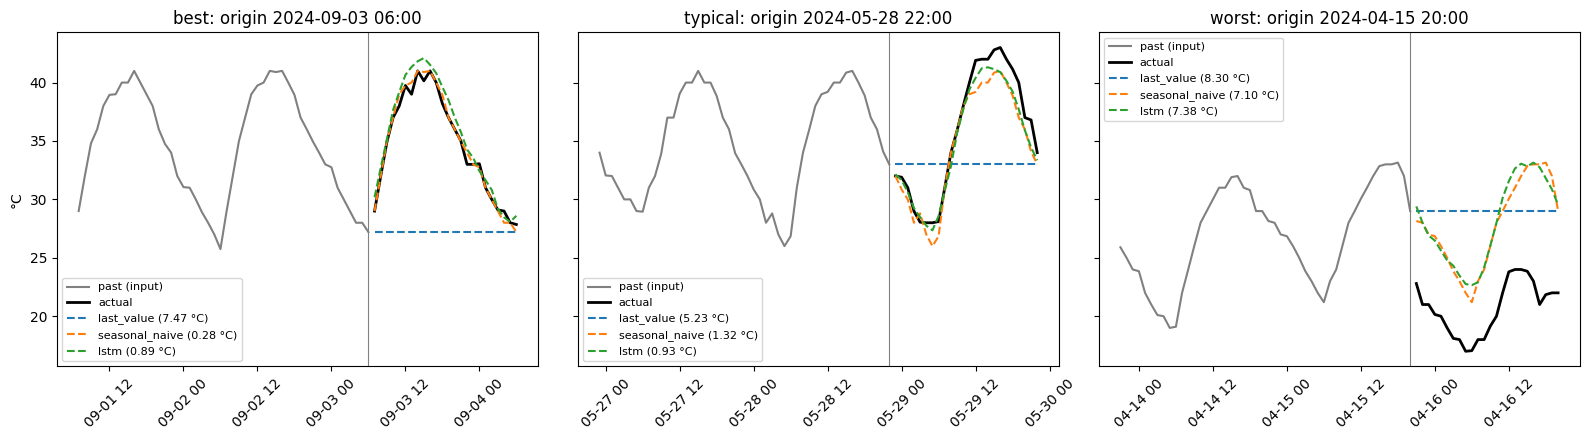

In [30]:
# P3-B4. Forecasts against actual values: best, typical and worst day (chosen by seasonal naive error)
err = {name: np.abs(EVAL_ACTUAL - p) for name, p in val_preds.items()}
day_err = err["seasonal_naive"].mean(axis=1)
picks = {"best": day_err.argmin(),
         "typical": np.abs(day_err - np.median(day_err)).argmin(),
         "worst": day_err.argmax()}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for a, (label, k) in zip(ax, picks.items()):
    t = EVAL_ORIGINS[k]
    past = hourly.loc[t - pd.Timedelta(hours=47): t]
    tt = t + pd.to_timedelta(STEPS, unit="h")
    a.plot(past.index, past.values, color="grey", label="past (input)")
    a.plot(tt, EVAL_ACTUAL[k], color="black", lw=2, label="actual")
    for name, p in val_preds.items():
        a.plot(tt, p[k], "--", label=f"{name} ({err[name][k].mean():.2f} °C)")
    a.axvline(t, color="grey", lw=0.8)
    a.set_title(f"{label}: origin {t:%Y-%m-%d %H:%M}")
    a.tick_params(axis="x", rotation=45)
    a.legend(fontsize=8)
ax[0].set_ylabel("°C")
plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
fig.savefig("../reports/figures/07_all_models_examples.png", dpi=150, bbox_inches="tight")

### B5: Where does the LSTM improve? (by horizon and by month)

MAE (°C) at 1 h, 12 h and 24 h ahead:


,last_value,seasonal_naive,lstm
hours ahead,,,
1,1.13,1.68,0.71
12,7.57,1.70,1.55
24,1.72,1.72,1.71


MAE (°C) by month:


,last_value,seasonal_naive,lstm
month,,,
1,5.04,1.84,1.54
2,4.67,3.13,2.51
3,3.51,2.89,2.47
4,4.78,2.58,2.13
5,5.17,2.16,1.66
6,5.82,1.06,1.00
7,5.24,0.85,0.86
8,5.49,1.01,0.89
9,5.22,0.97,0.99


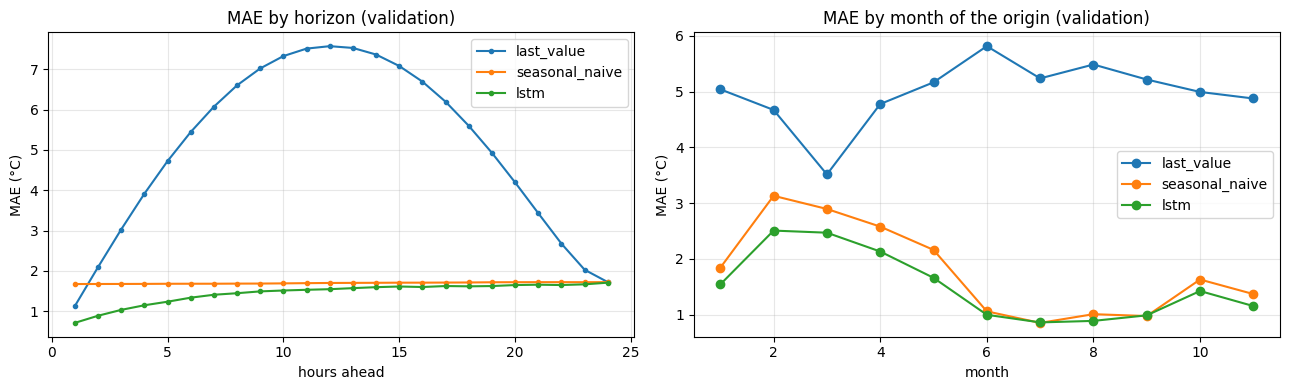

In [31]:
# P3-B5. Where does the LSTM improve? MAE by horizon and by month (same origins)
month = EVAL_ORIGINS.month
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, e in err.items():
    ax[0].plot(STEPS, e.mean(axis=0), marker="o", ms=3, label=name)
    pd.Series(e.mean(axis=1)).groupby(month).mean().plot(ax=ax[1], marker="o", label=name)
ax[0].set(title="MAE by horizon (validation)", xlabel="hours ahead", ylabel="MAE (°C)")
ax[1].set(title="MAE by month of the origin (validation)", xlabel="month", ylabel="MAE (°C)")
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout()
fig.savefig("../reports/figures/08_all_models_error.png", dpi=150, bbox_inches="tight")

by_h = pd.DataFrame({n: e.mean(axis=0) for n, e in err.items()}, index=pd.Index(STEPS, name="hours ahead"))
by_m = pd.DataFrame({n: pd.Series(e.mean(axis=1)).groupby(month).mean() for n, e in err.items()})
by_m.index.name = "month"
print("MAE (°C) at 1 h, 12 h and 24 h ahead:")
display(by_h.loc[[1, 12, 24]].round(2))
print("MAE (°C) by month:")
display(by_m.round(2))

### B6: Experiment log

In [32]:
# P3-B6. Experiment log: settings of every approach on the same evaluation dates
EXPERIMENTS = [
    {"model": "last_value", "inputs": "temp at t", "window_h": 1, "horizon_h": HORIZON,
     "settings": "repeat y[t] for 24 h", "trained": False},
    {"model": "seasonal_naive", "inputs": "temp t-23 … t", "window_h": 24, "horizon_h": HORIZON,
     "settings": "y[t+h-24] (same hour yesterday)", "trained": False},
    {"model": "lstm", "inputs": "temp t-71 … t (scaled, train-only scaler)", "window_h": WINDOW,
     "horizon_h": HORIZON, "trained": True,
     "settings": (f"LSTM({LSTM_CONFIG['units']}) + Dense({HORIZON}) | Adam lr {LSTM_CONFIG['lr']} | "
                  f"batch {LSTM_CONFIG['batch_size']} | max {LSTM_CONFIG['max_epochs']} epochs, "
                  f"patience {LSTM_CONFIG['patience']} | seed {SEED} | "
                  f"ran {LSTM_CONFIG['epochs_run']} epochs, best weights from epoch {LSTM_CONFIG['best_epoch']}")},
]
exp_log = (pd.DataFrame(EXPERIMENTS)
           .merge(final_results[["approach", "MAE", "RMSE"]], left_on="model", right_on="approach")
           .drop(columns="approach"))
exp_log["eval_dates"] = f"{EVAL_ORIGINS[0]:%Y-%m-%d %H:%M} → {EVAL_ORIGINS[-1]:%Y-%m-%d %H:%M} ({len(EVAL_ORIGINS)} origins)"
exp_log.to_csv("../reports/experiment_log.csv", index=False)
pd.set_option("display.max_colwidth", None)
display(exp_log)

,model,inputs,window_h,horizon_h,settings,trained,MAE,RMSE,eval_dates
0,last_value,temp at t,1,24,repeat y[t] for 24 h,False,5.078,6.332,2024-01-04 02:00 → 2024-11-25 23:00 (4321 origins)
1,seasonal_naive,temp t-23 … t,24,24,y[t+h-24] (same hour yesterday),False,1.701,2.418,2024-01-04 02:00 → 2024-11-25 23:00 (4321 origins)
2,lstm,"temp t-71 … t (scaled, train-only scaler)",72,24,"LSTM(32) + Dense(24) | Adam lr 0.001 | batch 64 | max 20 epochs, patience 3 | seed 42 | ran 20 epochs, best weights from epoch 18",True,1.456,2.019,2024-01-04 02:00 → 2024-11-25 23:00 (4321 origins)


#### Findings (Afternoon Track B)
- All three approaches are scored on the same **4,321 validation origins** (2024-01-04 02:00 → 2024-11-25 23:00), the same 24-hour horizon and the same metrics in °C.
- **LSTM:** MAE **1.46 °C**, RMSE **2.02 °C**, vs seasonal naive MAE 1.70 °C, RMSE 2.42 °C (about 14% lower MAE, 17% lower RMSE). Last-value is far behind (MAE 5.08 °C).
- See B5 for where the gain comes from (by horizon and by month) and B4 for example days.
- Validation was also used for early stopping, so the LSTM score may be slightly optimistic. The test period (2025) stays untouched for the final check.
- To compare a new model later: produce a (4321, 24) prediction in °C and call `evaluate(name, pred)`. The evaluation dates never change.
- **By horizon (B5):** the LSTM gains most in the first hours (1 h ahead: 0.71 °C vs 1.68 seasonal naive, 1.13 last-value). At 12 h it is still better (1.55 vs 1.70), but at 24 h it is the same as seasonal naive (1.71 vs 1.72).
- **By month (B5):** biggest gains in spring, when weather changes most (Feb 2.51 vs 3.13, Mar 2.47 vs 2.89, Apr 2.13 vs 2.58, May 1.66 vs 2.16). In summer (Jun–Sep) both are already good (~0.9–1.0 °C) and almost equal.
- The improvement is 14.5% on MAE and 16.5% on RMSE (B2 table).

# Required Tuesday deliverable
- [x] The time-based train, validation and test periods are documented
- [x] Input windows and forecast targets are aligned correctly
- [x] Scaling uses training data only
- [x] Last-value or seasonal-naive baseline results are saved
- [x] A small LSTM trains and predicts the chosen horizon
- [x] All approaches use the same dates and metric
- [x] The latest test period has not been used for tuning

**Do not choose the final model yet.**

## Ask together
- Do we all use the same date ranges, horizon and metric?
- Are windows and scaling correct?
- Can we reproduce the baseline and LSTM results?
- Can every person explain which past observations are used to predict which future values?

## Pitfalls
- Do not shuffle time order
- Do not leak future values (windows, features, scaler)
- Do not compare different dates
- Do not assume an LSTM is automatically better — explain the result honestly, even if the baseline wins

## What still needs work for Day 3
-